# Consumer Credit Risk Analysis

## Objective
Examine how observed next-month default rates vary across credit limits
and repayment histories in a sample of 30,000 credit card clients.

## Dataset
The analysis uses the UCI Default of Credit Card Clients dataset,
containing information on credit card clients in Taiwan and repayment
history from April to September 2005.

The outcome variable records whether a client defaulted in the following
month: 1 indicates default and 0 indicates no default.

Credit limits and monetary amounts are expressed in New Taiwan dollars (NT$).

## Questions
1. What is the overall default rate in the sample?
2. How does default rate vary by September repayment status?
3. How does default rate vary across credit-limit bands?
4. How does default rate vary with the number of months recording a delay?
5. Do differences by repayment status persist within credit-limit bands?

## Approach
Use Python, pandas, and Matplotlib to validate the data, construct groups,
calculate observed default rates, and visualise comparisons.

This is a descriptive analysis. It does not estimate causal effects or
provide a validated predictive model.

In [1]:
import sys

print(sys.executable)

e:\Projects\Data w python\.venv\Scripts\python.exe


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel(
    "default of credit card clients.xls",
    sheet_name="Data",
    header=1
)

df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
from IPython.display import display

# Create a working copy and shorten the outcome column name. 
# 
data = df.copy()
data = data.rename(
    columns={"default payment next month": "default"}
)

# Basic data-quality checks.
checks = pd.Series({
    "Number of rows": len(data),
    "Number of columns": data.shape[1],
    "Missing cells": data.isna().sum().sum(),
    "Duplicate client IDs": data["ID"].duplicated().sum(),
    "Duplicate complete rows": data.duplicated().sum(),
    "Invalid default values": (~data["default"].isin([0, 1])).sum(),
    "Non-positive credit limits": (data["LIMIT_BAL"] <= 0).sum()
}, name="Result")

display(checks.to_frame())

# Inspect the stored types and missing values for every column.
column_checks = pd.DataFrame({
    "Data type": data.dtypes.astype(str),
    "Missing values": data.isna().sum(),
    "Distinct values": data.nunique()
})

display(column_checks)

# Inspect category codes without changing or deleting them.
category_columns = [
    "SEX", "EDUCATION", "MARRIAGE",
    "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"
]

category_codes = pd.DataFrame({
    "Column": category_columns,
    "Observed codes": [
        sorted(data[column].dropna().unique().tolist())
        for column in category_columns
    ]
})

display(category_codes)

,Result
Number of rows,30000
Number of columns,25
Missing cells,0
Duplicate client IDs,0
Duplicate complete rows,0
Invalid default values,0
Non-positive credit limits,0


,Data type,Missing values,Distinct values
ID,int64,0,30000
LIMIT_BAL,int64,0,81
SEX,int64,0,2
EDUCATION,int64,0,7
MARRIAGE,int64,0,4
AGE,int64,0,56
PAY_0,int64,0,11
PAY_2,int64,0,11
PAY_3,int64,0,11
PAY_4,int64,0,11


,Column,Observed codes
0,SEX,"[1, 2]"
1,EDUCATION,"[0, 1, 2, 3, 4, 5, 6]"
2,MARRIAGE,"[0, 1, 2, 3]"
3,PAY_0,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]"
4,PAY_2,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]"
5,PAY_3,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]"
6,PAY_4,"[-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]"
7,PAY_5,"[-2, -1, 0, 2, 3, 4, 5, 6, 7, 8]"
8,PAY_6,"[-2, -1, 0, 2, 3, 4, 5, 6, 7, 8]"


In [4]:
# Stop if the outcome is missing or contains values other than 0 and 1.
assert data["default"].isin([0, 1]).all(), "Check the default column."

total_clients = len(data)
total_defaults = int(data["default"].sum())
overall_default_rate = data["default"].mean()

print(f"Total clients: {total_clients:,}")
print(f"Clients with default: {total_defaults:,}")
print(f"Clients without default: {total_clients - total_defaults:,}")
print(f"Overall default rate: {overall_default_rate:.2%}")

# Group clients by September repayment status.
repayment_summary = (
    data.groupby("PAY_0")["default"]
    .agg(
        clients="size",
        defaults="sum",
        default_rate="mean"
    )
    .sort_index()
)

# Compare each group's rate with the overall rate.
repayment_summary["difference_pp"] = (
    repayment_summary["default_rate"] - overall_default_rate
) * 100

# Use documented meanings; retain unclear codes explicitly.
status_labels = {
    -2: "Code -2: undocumented",
    -1: "Pay duly",
     0: "Code 0: undocumented"
}

repayment_summary["status"] = [
    status_labels.get(code, f"{code}-month payment delay")
    for code in repayment_summary.index
]

repayment_summary = repayment_summary[
    ["status", "clients", "defaults", "default_rate", "difference_pp"]
]

display(
    repayment_summary.style.format({
        "clients": "{:,.0f}",
        "defaults": "{:,.0f}",
        "default_rate": "{:.2%}",
        "difference_pp": "{:+.2f}"
    })
)

Total clients: 30,000
Clients with default: 6,636
Clients without default: 23,364
Overall default rate: 22.12%


,status,clients,defaults,default_rate,difference_pp
PAY_0,,,,,
-2,Code -2: undocumented,"2,759",365,13.23%,-8.89
-1,Pay duly,"5,686",954,16.78%,-5.34
0,Code 0: undocumented,"14,737","1,888",12.81%,-9.31
1,1-month payment delay,"3,688","1,252",33.95%,+11.83
2,2-month payment delay,"2,667","1,844",69.14%,+47.02
3,3-month payment delay,322,244,75.78%,+53.66
4,4-month payment delay,76,52,68.42%,+46.30
5,5-month payment delay,26,13,50.00%,+27.88
6,6-month payment delay,11,6,54.55%,+32.43


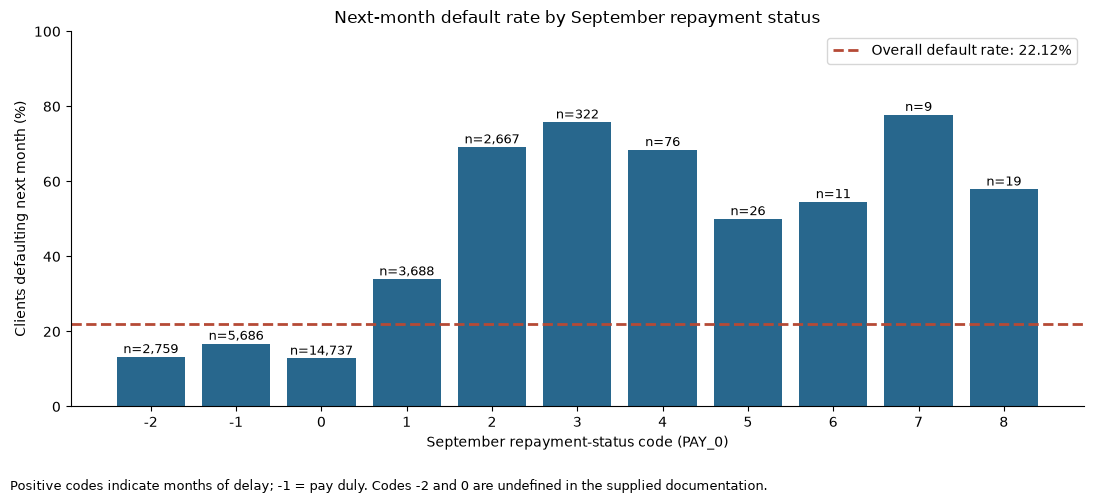

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    repayment_summary.index.astype(str),
    repayment_summary["default_rate"] * 100,
    color="#28678D"
)

ax.axhline(
    overall_default_rate * 100,
    color="#B54A36",
    linestyle="--",
    linewidth=2,
    label=f"Overall default rate: {overall_default_rate:.2%}"
)

# Show the number of clients above each bar.
for bar, count in zip(bars, repayment_summary["clients"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"n={count:,}",
        ha="center",
        fontsize=9
    )

ax.set(
    title="Next-month default rate by September repayment status",
    xlabel="September repayment-status code (PAY_0)",
    ylabel="Clients defaulting next month (%)",
    ylim=(0, 100)
)

ax.legend()
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.01, 0.01,
    "Positive codes indicate months of delay; -1 = pay duly. "
    "Codes -2 and 0 are undefined in the supplied documentation.",
    fontsize=9
)

plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

In [6]:
# ANALYSIS 2: Default rates by credit-limit band
# All amounts are in New Taiwan dollars (NT$).
# Each interval includes its upper boundary:
# e.g. 50,000 belongs to the first band.

credit_bins = [0, 50_000, 100_000, 200_000, 300_000, float("inf")]
credit_labels = [
    "Up to 50,000",
    "50,001–100,000",
    "100,001–200,000",
    "200,001–300,000",
    "Above 300,000"
]

data["credit_limit_band"] = pd.cut(
    data["LIMIT_BAL"],
    bins=credit_bins,
    labels=credit_labels,
    right=True
)

credit_summary = (
    data.groupby("credit_limit_band", observed=True)["default"]
    .agg(
        clients="size",
        defaults="sum",
        default_rate="mean"
    )
)

credit_summary["difference_pp"] = (
    credit_summary["default_rate"] - overall_default_rate
) * 100


# ANALYSIS 3: Number of monthly records showing a payment delay
# These six columns cover September back to April 2005.

repayment_columns = [
    "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"
]

assert data[repayment_columns].notna().all().all(), (
    "Missing repayment values need investigation."
)

# Positive codes indicate a recorded payment delay.
# Count how many of the six monthly records have a positive code.
data["months_with_recorded_delay"] = (
    data[repayment_columns].gt(0).sum(axis=1)
)

history_summary = (
    data.groupby("months_with_recorded_delay")["default"]
    .agg(
        clients="size",
        defaults="sum",
        default_rate="mean"
    )
    .sort_index()
)

history_summary["difference_pp"] = (
    history_summary["default_rate"] - overall_default_rate
) * 100


# Check that every client and default appears in each summary.
for summary in [credit_summary, history_summary]:
    assert summary["clients"].sum() == len(data)
    assert summary["defaults"].sum() == data["default"].sum()

table_format = {
    "clients": "{:,.0f}",
    "defaults": "{:,.0f}",
    "default_rate": "{:.2%}",
    "difference_pp": "{:+.2f}"
}

print("DEFAULT RATE BY CREDIT LIMIT (NT$)")
display(credit_summary.style.format(table_format))

print("DEFAULT RATE BY NUMBER OF MONTHLY RECORDS WITH A DELAY")
display(history_summary.style.format(table_format))

DEFAULT RATE BY CREDIT LIMIT (NT$)


,clients,defaults,default_rate,difference_pp
credit_limit_band,,,,
"Up to 50,000","7,676","2,440",31.79%,+9.67
"50,001–100,000","4,822","1,244",25.80%,+3.68
"100,001–200,000","7,880","1,535",19.48%,-2.64
"200,001–300,000","5,059",812,16.05%,-6.07
"Above 300,000","4,563",605,13.26%,-8.86


DEFAULT RATE BY NUMBER OF MONTHLY RECORDS WITH A DELAY


,clients,defaults,default_rate,difference_pp
months_with_recorded_delay,,,,
0,"19,931","2,334",11.71%,-10.41
1,"4,426","1,320",29.82%,+7.70
2,"1,899",736,38.76%,+16.64
3,"1,154",587,50.87%,+28.75
4,951,545,57.31%,+35.19
5,298,171,57.38%,+35.26
6,"1,341",943,70.32%,+48.20


In [7]:
data[repayment_columns].gt(0).sum(axis=1)

0        2
1        2
2        0
3        0
4        0
        ..
29995    0
29996    0
29997    3
29998    1
29999    0
Length: 30000, dtype: int64

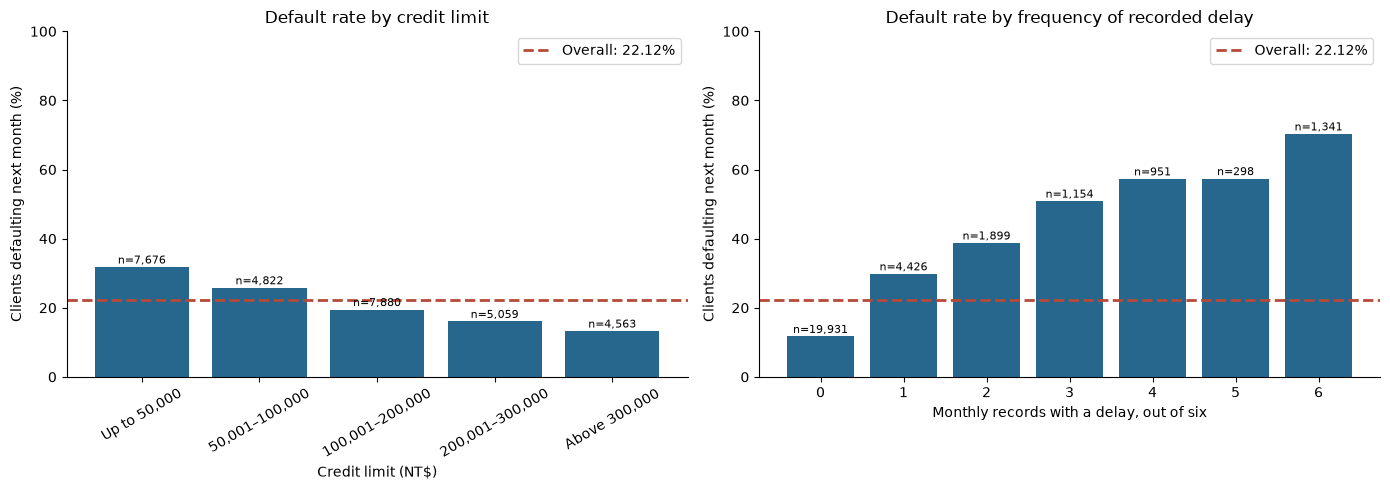

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

analyses = [
    (
        axes[0],
        credit_summary,
        "Default rate by credit limit",
        "Credit limit (NT$)"
    ),
    (
        axes[1],
        history_summary,
        "Default rate by frequency of recorded delay",
        "Monthly records with a delay, out of six"
    )
]

for ax, summary, title, xlabel in analyses:
    bars = ax.bar(
        summary.index.astype(str),
        summary["default_rate"] * 100,
        color="#28678D"
    )

    ax.axhline(
        overall_default_rate * 100,
        color="#B54A36",
        linestyle="--",
        linewidth=2,
        label=f"Overall: {overall_default_rate:.2%}"
    )

    for bar, count in zip(bars, summary["clients"]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"n={count:,}",
            ha="center",
            fontsize=8
        )

    ax.set(
        title=title,
        xlabel=xlabel,
        ylabel="Clients defaulting next month (%)",
        ylim=(0, 100)
    )

    ax.spines[["top", "right"]].set_visible(False)
    ax.legend()

axes[0].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

NEXT-MONTH DEFAULT RATES


september_status_group,Code -2,Pay duly (-1),Code 0,1-month delay,2+ months delay
credit_limit_band,,,,,
"Up to 50,000",10.92%,25.75%,19.19%,42.25%,69.07%
"50,001–100,000",9.14%,21.25%,13.93%,34.97%,71.35%
"100,001–200,000",13.11%,17.09%,10.67%,29.81%,69.33%
"200,001–300,000",13.20%,15.72%,7.77%,26.85%,68.10%
"Above 300,000",14.74%,9.10%,7.10%,28.15%,68.94%


NUMBER OF CLIENTS IN EACH GROUP


september_status_group,Code -2,Pay duly (-1),Code 0,1-month delay,2+ months delay
credit_limit_band,,,,,
"Up to 50,000",174,804,"4,205","1,174","1,319"
"50,001–100,000",186,607,"2,721",589,719
"100,001–200,000",793,"1,790","3,719",926,652
"200,001–300,000",765,"1,298","2,162",555,279
"Above 300,000",841,"1,187","1,930",444,161


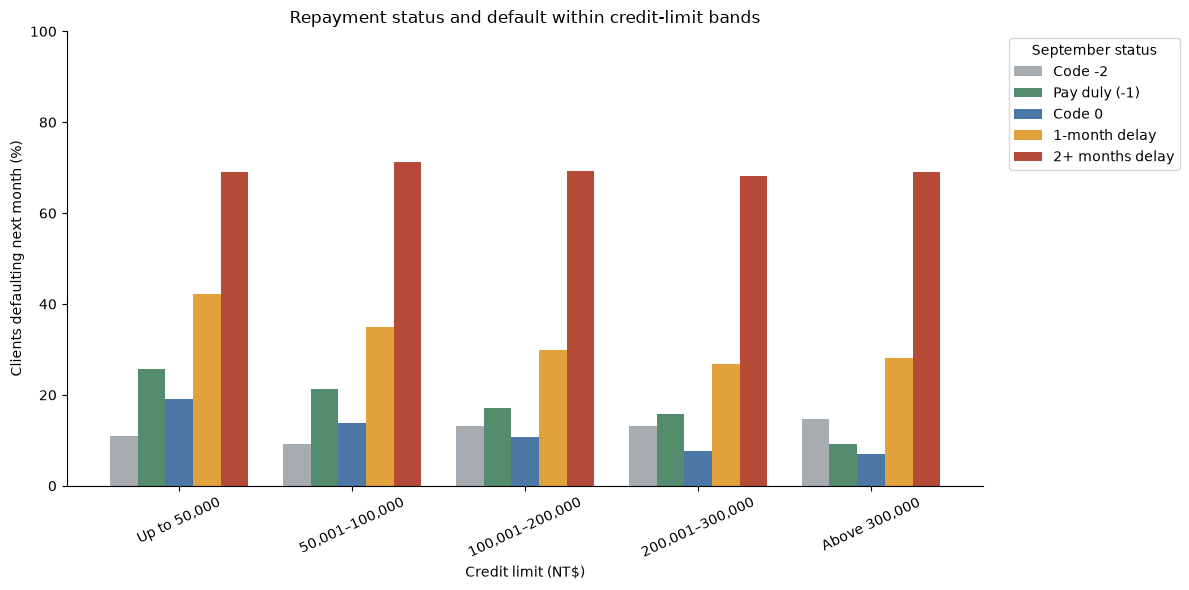

In [9]:
# Preserve the non-positive codes separately.
# Combine longer delays to avoid many very small groups.

september_groups = {
    -2: "Code -2",
    -1: "Pay duly (-1)",
     0: "Code 0",
     1: "1-month delay",
     2: "2+ months delay",
     3: "2+ months delay",
     4: "2+ months delay",
     5: "2+ months delay",
     6: "2+ months delay",
     7: "2+ months delay",
     8: "2+ months delay",
     9: "2+ months delay"
}

group_order = [
    "Code -2",
    "Pay duly (-1)",
    "Code 0",
    "1-month delay",
    "2+ months delay"
]

data["september_status_group"] = data["PAY_0"].map(september_groups)

assert data["september_status_group"].notna().all(), (
    "An unexpected repayment code needs investigation."
)

# Each row now represents a combination of credit limit and repayment status.
combined_summary = (
    data.groupby(
        ["credit_limit_band", "september_status_group"],
        observed=True
    )["default"]
    .agg(
        clients="size",
        defaults="sum",
        default_rate="mean"
    )
    .reset_index()
)

assert combined_summary["clients"].sum() == len(data)
assert combined_summary["defaults"].sum() == data["default"].sum()

# Arrange results into tables:
# rows = credit-limit bands; columns = repayment-status groups.
rate_table = combined_summary.pivot(
    index="credit_limit_band",
    columns="september_status_group",
    values="default_rate"
).reindex(columns=group_order)

count_table = combined_summary.pivot(
    index="credit_limit_band",
    columns="september_status_group",
    values="clients"
).reindex(columns=group_order)

print("NEXT-MONTH DEFAULT RATES")
display(rate_table.style.format("{:.2%}", na_rep="No clients"))

print("NUMBER OF CLIENTS IN EACH GROUP")
display(count_table.style.format("{:,.0f}", na_rep="0"))

# Compare repayment groups within each credit-limit band.
ax = (rate_table * 100).plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8,
    color=["#A6ACAF", "#548C70", "#4C78A8", "#E3A13B", "#B54A36"]
)

ax.set(
    title="Repayment status and default within credit-limit bands",
    xlabel="Credit limit (NT$)",
    ylabel="Clients defaulting next month (%)",
    ylim=(0, 100)
)

ax.tick_params(axis="x", rotation=25)
ax.legend(title="September status", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## Findings and interpretation

The sample contains 30,000 credit-card clients, 6,636 defaulted in the following month. The overall default rate being 22.12%.

### Credit limits

Default rates decrease across the selected credit-limit bands: 31.79% for limits up to NT$50,000, compared with 13.26% for limits above NT$300,000.

This  does not imply that increasing credit limits reduces default risk. Existing lending decisions and differences between customers may help explain the pattern.

### Repayment history

Clients with no positive delay codes across the six monthly records have a default rate of 11.71%. Those with positive delay codes in all six records have a default rate of 70.32%.

The above takes into account only the monthly records showing delay. It does not count seprate missed-payment events, an overdue balance can persist across multiple months.

### Repayment status within credit-limit bands

For clients with a September payment delay of two or more months, default rates range from 68.10% to 71.35% across the five credit-limit bands.

The association between substantial recent delays and elevated default risk therefore persists within each credit-limit band. Higher credit limits alone do not identify low-risk clients when substantial repayment delays are present.

### Implications for further investigation

Recent repayment delays and repeated records of delay are useful candidates for account-monitoring indicators.

Any proposed monitoring rule should be evaluated on seprate data, with attention to how many customers it flags, how many defaults it identifies, and how many flagged customers do not default. This analysis does not establish the effectiveness of an intervention.

## Limitations

-> The data concern credit-card clients in Taiwan, with repayment history from April to September 2005. Findings may not transfer to current Indian or other lending markets.
-> Repayment codes -2 and 0 are not defined in the supplied UCI description. They were retained separately in September-status comparisons.
-> Zero monthly records with positive delay codes should not be interpreted as proof that all payments were made on time. The payment might be delayed by days and not full months. A crucial limitation of this dataset.
-> Credit-limit bands were chosen for interpretability, alternative boundaries may produce different group summaries.
-> Group sizes vary, and rates based on smaller groups are less precise.
-> The analysis is descriptive. It does not establish causation, provide validated individual default probabilities, or estimate financial losses.
-> The supplied description identifies the binary default outcome but does not specify a detailed operational default threshold.